# Wind forecast error analysis: January 2026

**Question.** The buying team commits to day-ahead purchases using the wind forecast available at decision time. How wrong is that forecast, and how much error should they plan for?

**Data.** Elexon BMRS, national level, same sources as the app:
- Actuals: `FUELHH`, `fuelType = WIND`, half-hourly.
- Forecasts: `WINDFOR`, hourly targets, many vintages per target (`publishTime`).

**Method.** For a forecast horizon *h*, each target hour uses the **latest forecast published at least *h* hours before it** (no look-ahead), capped at 48h. Error = actual − forecast, so a negative error means wind came in below forecast and extra power had to be bought.

In [1]:
import httpx
import matplotlib.pyplot as plt
import pandas as pd

BASE = "https://data.elexon.co.uk/bmrs/api/v1/datasets"
START, END = pd.Timestamp("2026-01-01", tz="UTC"), pd.Timestamp("2026-02-01", tz="UTC")
MAX_H = 48

with httpx.Client(timeout=60) as client:
    fuel = client.get(f"{BASE}/FUELHH/stream", params={"settlementDateFrom": "2025-12-31", "settlementDateTo": "2026-01-31", "fuelType": "WIND"}).json()
    wind = client.get(f"{BASE}/WINDFOR/stream", params={"publishDateTimeFrom": "2025-12-30T00:00:00Z", "publishDateTimeTo": "2026-02-01T00:00:00Z"}).json()

actuals = pd.DataFrame(fuel).assign(target=lambda d: pd.to_datetime(d.startTime, utc=True))[["target", "generation"]].rename(columns={"generation": "actual"})
actuals = actuals[(actuals.target >= START) & (actuals.target < END)].drop_duplicates("target").sort_values("target")

forecasts = pd.DataFrame(wind).assign(
    target=lambda d: pd.to_datetime(d.startTime, utc=True),
    published=lambda d: pd.to_datetime(d.publishTime, utc=True),
)[["target", "published", "generation"]].rename(columns={"generation": "forecast"})
forecasts["lead_h"] = (forecasts.target - forecasts.published).dt.total_seconds() / 3600
forecasts = forecasts[(forecasts.target >= START) & (forecasts.target < END) & forecasts.lead_h.between(0, MAX_H)].drop_duplicates(["target", "published"])

print(f"{len(actuals)} half-hourly actuals, {len(forecasts)} forecast rows covering {forecasts.target.nunique()} target hours")
print(f"forecast runs per day: {forecasts.published.drop_duplicates().dt.floor('D').value_counts().mean():.1f}")

1488 half-hourly actuals, 11873 forecast rows covering 744 target hours
forecast runs per day: 8.0


In [2]:
def at_horizon(h: int) -> pd.DataFrame:
    eligible = forecasts[forecasts.lead_h >= h].sort_values("published")
    latest = eligible.groupby("target").tail(1)
    out = latest.merge(actuals, on="target")
    out["error"] = out.actual - out.forecast
    return out

def summarise(df: pd.DataFrame) -> pd.Series:
    e = df.error
    return pd.Series({
        "hours": len(df),
        "MAE": e.abs().mean(),
        "RMSE": (e ** 2).mean() ** 0.5,
        "bias": e.mean(),
        "nMAE %": 100 * e.abs().mean() / df.actual.mean(),
        "P90 |err|": e.abs().quantile(0.9),
        "P10 err": e.quantile(0.1),
    })

by_horizon = pd.DataFrame({h: summarise(at_horizon(h)) for h in range(0, MAX_H)}).T
by_horizon.loc[[0, 1, 4, 8, 12, 24, 36, 47]].round(0)

,hours,MAE,RMSE,bias,nMAE %,P90 |err|,P10 err
0,744.0,1794.0,2281.0,-1592.0,15.0,3764.0,-3764.0
1,744.0,1801.0,2294.0,-1596.0,16.0,3798.0,-3798.0
4,744.0,1836.0,2332.0,-1645.0,16.0,3899.0,-3899.0
8,744.0,1887.0,2362.0,-1694.0,16.0,3906.0,-3906.0
12,744.0,1898.0,2379.0,-1704.0,16.0,3897.0,-3897.0
24,744.0,2050.0,2518.0,-1854.0,18.0,4129.0,-4129.0
36,744.0,2258.0,2750.0,-1951.0,20.0,4263.0,-4263.0
47,217.0,2492.0,3041.0,-2088.0,22.0,4867.0,-4736.0


Horizons of 47h and more have far fewer hours because forecast runs are not published exactly 48h ahead of every target, so 0–46h is the reliable range.

## 1. Error grows with lead time

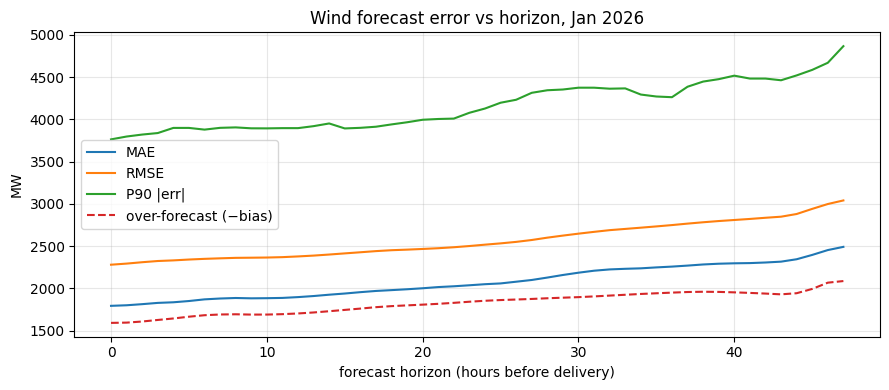

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
by_horizon[["MAE", "RMSE", "P90 |err|"]].plot(ax=ax)
(-by_horizon["bias"]).plot(ax=ax, linestyle="--", label="over-forecast (−bias)")
ax.set(xlabel="forecast horizon (hours before delivery)", ylabel="MW", title="Wind forecast error vs horizon, Jan 2026")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout()

## 2. Day-ahead view (24h): error distribution

count     744.0
mean    -1854.0
std      1705.0
min     -6804.0
5%      -5097.0
10%     -4129.0
50%     -1709.0
90%       288.0
95%       804.0
max      2655.0
Name: error, dtype: float64

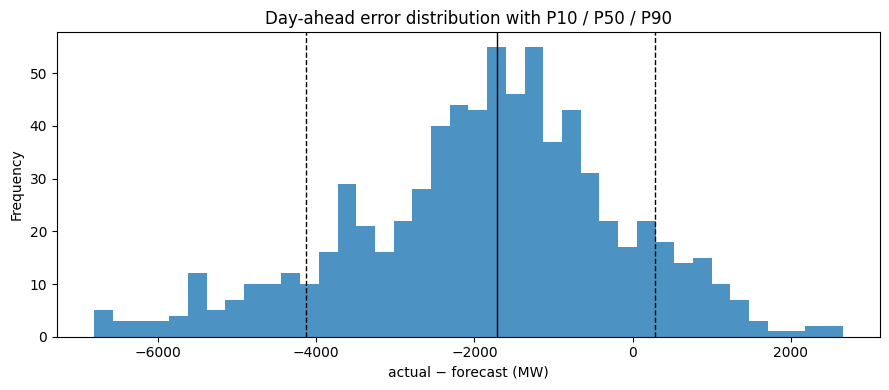

In [4]:
da = at_horizon(24)
fig, ax = plt.subplots(figsize=(9, 4))
da.error.plot.hist(bins=40, ax=ax, alpha=0.8)
for q, style in [(0.1, "--"), (0.5, "-"), (0.9, "--")]:
    ax.axvline(da.error.quantile(q), color="k", linestyle=style, linewidth=1)
ax.set(xlabel="actual − forecast (MW)", title="Day-ahead error distribution with P10 / P50 / P90")
plt.tight_layout()
da.error.describe(percentiles=[0.05, 0.1, 0.5, 0.9, 0.95]).round(0)

## 3. Is the error tied to the wind level?

In [5]:
da["band"] = pd.cut(da.forecast, bins=[0, 5000, 10000, 15000, 20000, 30000])
by_band = da.groupby("band", observed=True).apply(summarise, include_groups=False)[["hours", "MAE", "bias", "nMAE %"]].round(0)
by_band

,hours,MAE,bias,nMAE %
band,,,,
"(0, 5000]",34.0,1155.0,-720.0,33.0
"(5000, 10000]",185.0,1434.0,-1030.0,20.0
"(10000, 15000]",205.0,1450.0,-1212.0,13.0
"(15000, 20000]",274.0,2601.0,-2574.0,17.0
"(20000, 30000]",46.0,4583.0,-4583.0,29.0


## 4. Time-of-day pattern (24h horizon)

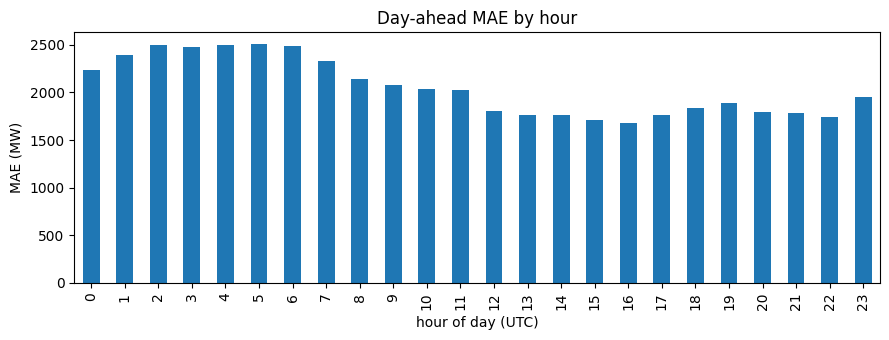

In [6]:
by_hour = da.groupby(da.target.dt.hour).apply(summarise, include_groups=False)
fig, ax = plt.subplots(figsize=(9, 3.5))
by_hour["MAE"].plot.bar(ax=ax)
ax.set(xlabel="hour of day (UTC)", ylabel="MAE (MW)", title="Day-ahead MAE by hour")
plt.tight_layout()

## 5. From error to a buying rule

In [7]:
rule = pd.DataFrame({
    "horizon_h": [4, 12, 24, 36],
    "buffer_P10_MW": [-by_horizon.loc[h, "P10 err"] for h in [4, 12, 24, 36]],
    "buffer_P05_MW": [-at_horizon(h).error.quantile(0.05) for h in [4, 12, 24, 36]],
}).round(0)
rule

,horizon_h,buffer_P10_MW,buffer_P05_MW
0,4,3899.0,4672.0
1,12,3897.0,4591.0
2,24,4129.0,5097.0
3,36,4263.0,5422.0


## Conclusions

1. **The forecast is systematically optimistic.** At the day-ahead horizon (24h), actual wind came in ~1.85 GW below forecast on average, and below forecast in 87% of hours. Most of the error is bias, not noise: MAE 2.05 GW vs bias −1.85 GW.
2. **The bias scales with wind level.** Above 20 GW forecast, the entire error is over-forecast (MAE = −bias ≈ 4.6 GW). A likely cause is that high-wind periods are when transmission constraints curtail wind farms, which WINDFOR does not net off. This is a hypothesis to validate with the client against balancing-mechanism data.
3. **Lead time matters, but less than bias.** MAE rises from 1.79 GW (0h) to 2.05 GW (24h) and 2.26 GW (36h), about 26% worse from 0h to 36h.
4. **Buying rule.** At 24h, procuring a buffer of ~4.1 GW below forecast covers 90% of hours (P10 error); ~5.1 GW covers 95%. The app shows this buffer live for any horizon and date range.
5. **Next step.** A simple bias correction scaled by forecast level would remove most of the error. That is the natural phase-two feature.